# Feature correlations: heatmap and observations

**Question:** Which numeric features are associated with consumption, and which predictors contain similar information?

This notebook contains the full correlation heatmap, a supporting table and short observations. No rows are dropped, no missing values are filled, and no features are removed from the original dataframe. Constant columns are excluded only from the correlation calculation because their correlations are undefined.

Place `dataset_mansion.csv` beside this notebook or change the path below. Code has been executed and the results are included.

In [1]:
from pathlib import Path
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

path = Path('dataset_mansion.csv')
if not path.exists():
    path = Path('upload/dataset_mansion.csv')

df = pd.read_csv(path, index_col=0)
df['Consumption'] = pd.to_numeric(
    df['Consumption'].astype('string').str.replace(',', '.', regex=False),
    errors='raise'
)
# Source documentation specifies UTC timestamps.
df['MTime'] = pd.to_datetime(df['MTime'], utc=True, errors='raise')
df = df.set_index('MTime').sort_index()

# Select numeric columns and exclude constant features from this calculation.
numeric_df = df.select_dtypes(include='number')
numeric_df = numeric_df.loc[:, numeric_df.nunique(dropna=True) > 1]
assert 'Consumption' in numeric_df, 'Consumption must be numeric and nonconstant.'
corr_matrix = numeric_df.corr(method='pearson')

## 1. Full correlation heatmap

- **Red:** positive linear association; higher values tend to occur together.
- **Blue:** negative linear association; higher values of one tend to accompany lower values of the other.
- **Near white:** little linear association. Nonlinear relationships may still exist.

Values range from **−1 to +1**. The diagonal is 1 because each feature is correlated with itself. The matrix is symmetric, so either half contains the same information. An annotation of 1.00 can be a rounded value rather than an exact correlation of 1.

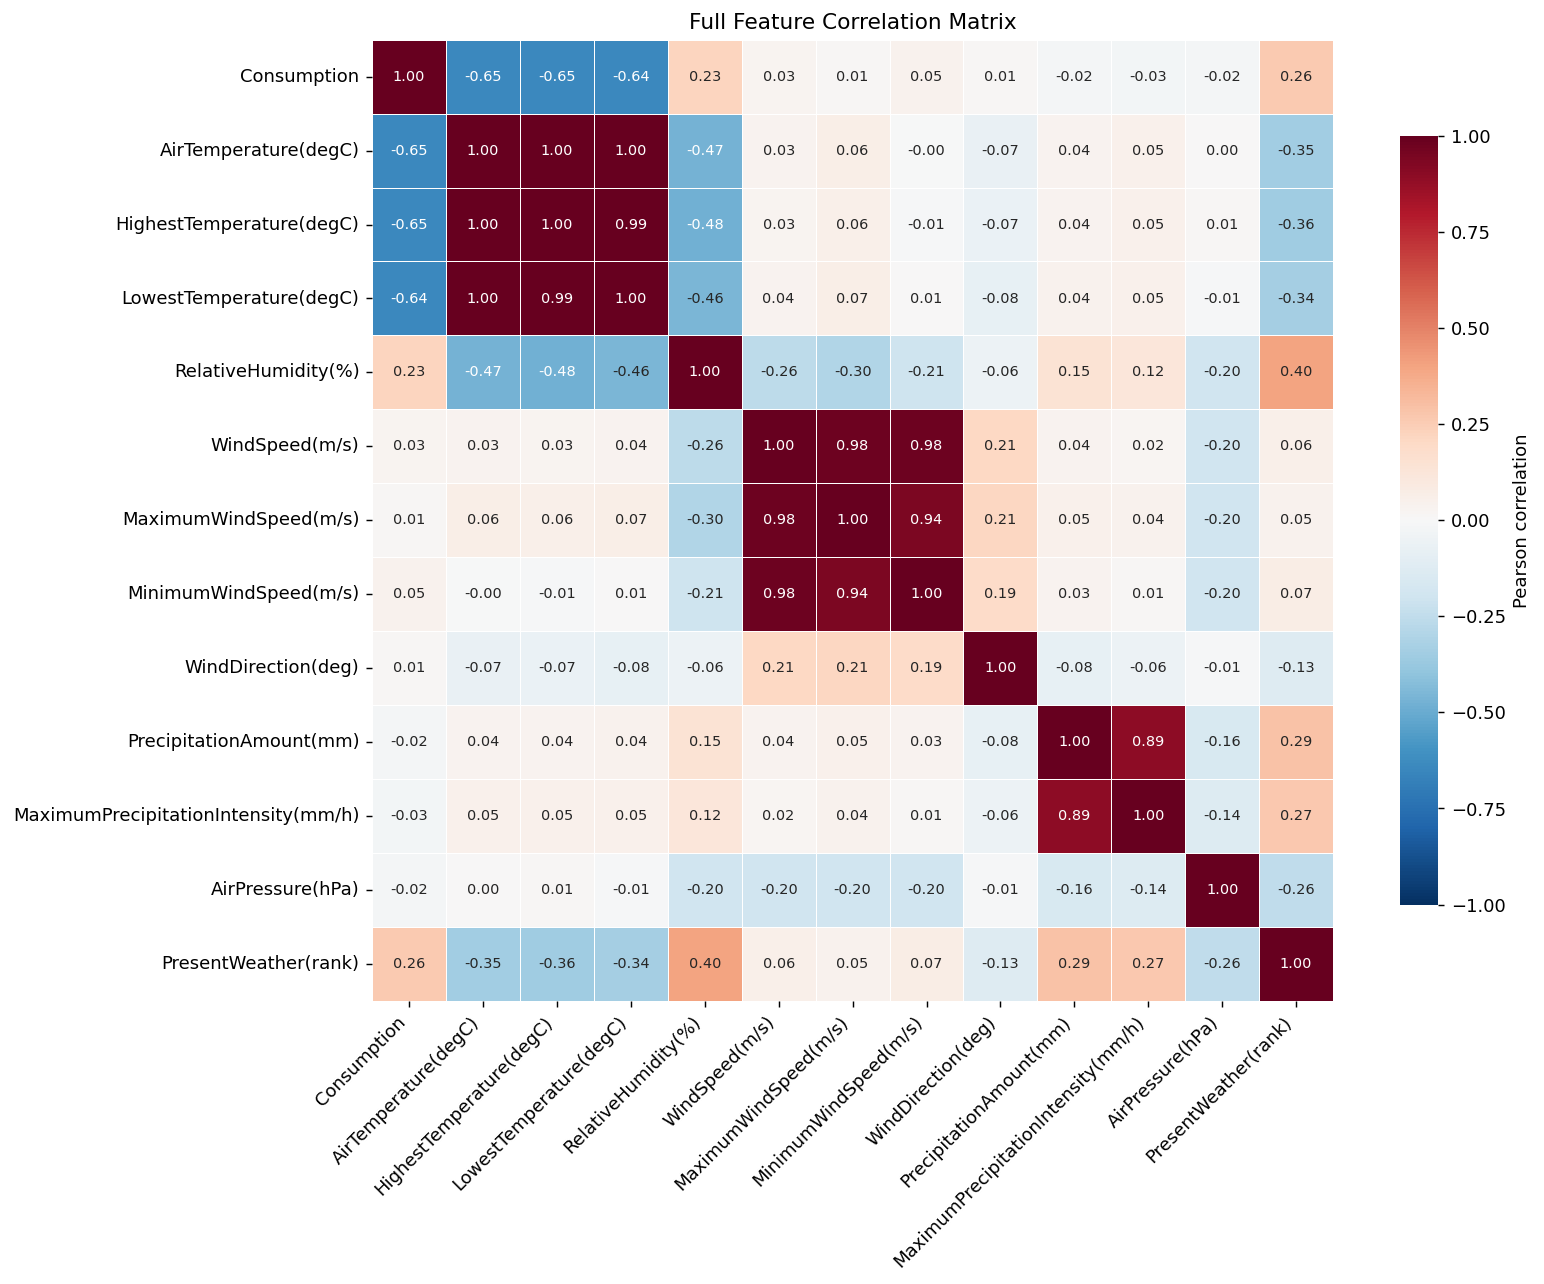

In [2]:
plt.figure(figsize=(13, 10))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='RdBu_r',
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    annot_kws={'size': 8},
    cbar_kws={'label': 'Pearson correlation', 'shrink': 0.8}
)
plt.title('Full Feature Correlation Matrix')
plt.xlabel('')
plt.ylabel('')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## 2. Observations

1. **Temperature has the strongest linear association with consumption.** Air, highest and lowest temperatures correlate with consumption at approximately **−0.65, −0.65 and −0.64**. Higher temperatures tend to coincide with lower consumption. This is consistent with heating demand, but shared seasonal patterns and other factors mean correlation alone does not establish the cause.
2. **The three temperature features are very similar.** Their pairwise correlations are approximately **0.99–1.00**. Keeping air temperature and testing whether the highest/lowest temperature add useful information is a reasonable later feature-engineering comparison.
3. **Wind-speed features are strongly related to one another**, approximately **0.94–0.98**, despite weak individual linear correlations with consumption. They are candidates for a redundancy check, not automatic deletion.
4. **Precipitation amount and maximum intensity correlate at approximately 0.89.** They share information, but describe different aspects of rainfall. Their near-zero correlations with consumption do not rule out other relationships.
5. **Humidity has a modest positive correlation with consumption (0.23).** Weather rank has a numerical correlation of **0.26**, but its coding is not sufficiently defined to assume equal numeric distances are meaningful. Its missing coverage also limits comparison with the other features.

Latitude and longitude each have one unique observed value, so they do not appear in the matrix. Place is text and is excluded by numeric selection. All three remain in `df`.

## 3. How many observations support the consumption correlations?

Pandas uses the rows where **both variables are available**, separately for every pair. It does not require an entire row to be complete. The table below shows the number of paired observations for correlations with consumption. For predictor-to-predictor cells, the paired count can differ again.

In [3]:
paired_counts = numeric_df.drop(columns='Consumption').apply(
    lambda column: (column.notna() & numeric_df['Consumption'].notna()).sum()
)
consumption_summary = pd.DataFrame({
    'Correlation with Consumption': corr_matrix['Consumption'].drop('Consumption'),
    'Paired observations': paired_counts
}).sort_values('Correlation with Consumption')
display(consumption_summary.round(3))

,Correlation with Consumption,Paired observations
HighestTemperature(degC),-0.646,56028
AirTemperature(degC),-0.645,56023
LowestTemperature(degC),-0.643,56028
MaximumPrecipitationIntensity(mm/h),-0.030,55910
AirPressure(hPa),-0.020,56021
PrecipitationAmount(mm),-0.018,55928
WindDirection(deg),0.010,55730
MaximumWindSpeed(m/s),0.013,55490
WindSpeed(m/s),0.028,55613
MinimumWindSpeed(m/s),0.047,55490


## What to record in the EDA

> Consumption is negatively associated with temperature. Temperature features and wind-speed features show strong within-group correlations, suggesting possible redundancy. Precipitation amount and maximum intensity are also strongly correlated. These are observations for later model comparisons, not final feature-removal decisions.

**Interpretation limits:**

- Weather rank uses only **23,790 paired observations** with consumption, compared with around 55,000–56,000 for other features. Its observed time periods differ, so the correlations are not all based on the same sample.
- Wind direction wraps around at 360°. Ordinary Pearson correlation on raw degrees can be misleading; investigate circular representations later.
- These are **same-hour, pooled linear associations**. They do not measure lagged effects, causality, nonlinear associations or model importance, and are not significance tests. Time trends, seasonality and autocorrelation can affect interpretation.

Keep the dataset unchanged during EDA. Later, compare feature sets using chronological validation. If the task is forecasting, also verify that each input would be available at the intended prediction time.